# DEX/No-DEX Footprinting

#### Files:

- `Glucocorticoid receptor (GR/NR3C1?) BED file`: List of genomic sites where GR binds [chromosome, start, end, name, score, strand]
    - Generated from JASPAR NR3C1 MA0113.1 MEME file using FIMO
- `Tn5 Bias File for Mice`: genome=scp.genome.mm10; already including in scPrinter
- `Fragment file`: 2 BAM files for dex/no-dex, converted to fragment tsv

In [1]:
import os
import platform
import numpy as np
import sys
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
ON_MAC = platform.system() == "Darwin"
if ON_MAC:
    os.environ.pop("SCPRINTER_DATA", None)   # Mac: use the default cache. On NRP, run_on_nrp.sh sets it to /data/scprinter_cache
import scprinter as scp
import scprinter.tools as _sct
from concurrent.futures import Future
import h5py

# Mac-only workaround: scPrinter's parallel workers fail on macOS, so run jobs one at a time.
# On NRP (Linux) the normal parallel workers are used, with n_jobs set by the job.
class _SerialExecutor:
    def __init__(self, *args, **kwargs): pass
    def submit(self, fn, *args, **kwargs):
        f = Future()
        try:
            f.set_result(fn(*args, **kwargs))
        except Exception as e:
            f.set_exception(e)
        return f
    def shutdown(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, *exc): self.shutdown()

if ON_MAC:
    _sct.ProcessPoolExecutor = _SerialExecutor

    # Mac-only memory fix: read Tn5 bias from the bigWig instead of loading the whole-genome .h5 (~11 GB)
    from scprinter.io import get_bias_insertions as _orig_get_bias
    def _get_bias_from_bw(printer, regions, bias_mode="h5", **kwargs):
        return _orig_get_bias(printer, regions, bias_mode="bw", **kwargs)
    _sct.get_bias_insertions = _get_bias_from_bw

import time
import pandas as pd
import pybedtools
import matplotlib.pyplot as plt
import re
import math
import copy
import pyBigWig
from tqdm import tqdm
from zipfile import ZipFile
import seaborn as sns
import scipy.stats as ss
import torch

/tmp/scprinter_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Where the data lives: NRP's job sets GR_WD and N_JOBS; on the Mac these fall back to the defaults
wd = os.environ.get("GR_WD", os.path.expanduser("~/Documents/GitHub/printing/data"))
n_jobs = int(os.environ.get("N_JOBS", "1"))

In [3]:
# Parameters
wd = "/data/GR_dex"
n_jobs = 8


In [4]:
os.makedirs(os.path.join(wd, "plots"), exist_ok=True)
print("wd:", wd, "| n_jobs:", n_jobs)

wd: /data/GR_dex | n_jobs: 8


In [5]:
barcodes = ['no_dex', 'dex']

### Load GR BED File

| Col | Content |
| --- | --- |
| 0 | chromosome |
| 1 | motif start (0-based, inclusive) |
| 2 | motif end (0-based, exclusive) |
| 3 | name + seq |
| 4 | p-value: smaller = stronger match to GR motif |
| 5 | negative/positive strand |

In [6]:
gr_bed = pd.read_table(os.path.join(wd, 'GR_motifs_mm10.bed'), header=None)
print('sites (filtered to p-val < 0.0001):', gr_bed.shape[0])
gr_bed.head(10)

sites (filtered to p-val < 0.0001): 519243


,0,1,2,3,4,5
0,chr1,3002020,3002038,GR_GAGAAGAAAACTTCCCAA,0.000015,-
1,chr1,3003351,3003369,GR_GAGAACAGTCTGTGCAGA,0.000070,-
2,chr1,3012791,3012809,GR_AAAAACAGTCAGTTGTGC,0.000061,+
3,chr1,3014633,3014651,GR_AAAACCAGCCTGACCAGG,0.000087,+
4,chr1,3021987,3022005,GR_AGAAGCATACAGAACTGT,0.000072,+
5,chr1,3023377,3023395,GR_GGAAACAAAAAGAACTAT,0.000033,+
6,chr1,3026770,3026788,GR_AGGAAAAAAATTTCCAAT,0.000074,-
7,chr1,3034095,3034113,GR_AAAAACATCATGTTCTAC,0.000001,-
8,chr1,3034271,3034289,GR_AGAAACAAAAAGAACTAT,0.000055,-
9,chr1,3036023,3036041,GR_AAGAAGATTATTTTCTTG,0.000029,+


### Download mm10 Files

In [7]:
scp.genome.mm10.fetch_bias()       # mouse Tn5 bias (.h5)
bw = scp.genome.mm10.fetch_bias_bw()
b = pyBigWig.open(bw); print(b.values("chr1", 3002020, 3002030)); b.close() 

[0.0876321941614151, 0.43210163712501526, 0.2552497982978821, 0.25499406456947327, 0.038610637187957764, 0.03572392463684082, 0.3674987554550171, 0.06727196276187897, 0.277785986661911, 0.0833393782377243]


In [8]:
# Loads GR_printer.h5ad if fragments were already imported; otherwise imports them
h5ad_path = os.path.join(wd, 'GR_printer.h5ad')
done_flag = os.path.join(wd, 'GR_printer.DONE') 

if os.path.exists(done_flag):
    print("Loading existing printer object...")
    printer = scp.load_printer(h5ad_path, scp.genome.mm10)
else:
    print("Importing fragments (first run, this takes a while)...")
    if os.path.exists(h5ad_path):
        os.remove(h5ad_path)            # clear any half-written file from an interrupted run
    printer = scp.pp.import_fragments(
        path_to_frags=os.path.join(wd, 'GR_all.frags.tsv.gz'),
        barcodes=barcodes,
        savename=h5ad_path,
        genome=scp.genome.mm10,
        sorted_by_barcode=True)
    open(done_flag, 'w').close()        # mark as finished

# Dispersion model: expected center/flank cut ratio on bare DNA, given Tn5 bias and coverage
printer.load_disp_model()

Loading existing printer object...


loading GR_dex_sites /data/GR_dex/GR_printer_supp/GR_dex_sites.h5ad


### Choose GR Sites to Footprint
- **Dex-responsive sites:** GR motifs that are accessible and open up with dex. The log2FC cutoff is chosen automatically: the strictest of `lfc_options` that still gives at least `target_sites` sites.
- **Control sites:** GR motifs that are accessible but *don't* change with dex (|log2FC| < 0.2). If a footprint appears with dex only at the dex-responsive sites, the effect is specific to GR activity.
- Run 1 used min_cuts > 200 and log2FC > 1, which left only 80 sites.

In [9]:
window = 500                          # count Tn5 cuts within ±500 bp of each motif center
min_cuts = 100                        # minimum cuts (both conditions combined) to count as accessible
lfc_options = [1, 0.75, 0.5, 0.25]    # tried in order; the strictest one giving >= target_sites is used
target_sites = 1000
max_sites = 3000                      # at most this many dex-responsive sites are footprinted
n_control = 500                       # number of unchanged control sites

gr_sites = gr_bed.copy()
gr_sites["center"] = (gr_sites[1] + gr_sites[2]) // 2

ins = printer.fetch_insertion_profile()
bc = list(printer.insertion_file.obs_names)
row_nodex, row_dex = bc.index("no_dex"), bc.index("dex")

cuts_nodex = np.zeros(len(gr_sites)); cuts_dex = np.zeros(len(gr_sites))
total_nodex = total_dex = 0
for chrom in tqdm(gr_sites[0].unique()):
    if chrom not in ins:
        continue
    m = ins[chrom]
    idx = np.where(gr_sites[0].values == chrom)[0]
    c = gr_sites["center"].values[idx]
    for row, out in [(row_nodex, cuts_nodex), (row_dex, cuts_dex)]:
        track = np.asarray(m[row].todense()).ravel()                    # one condition, one chromosome
        cs = np.concatenate([[0], np.cumsum(track, dtype=np.int64)])    # cumulative sum -> fast window sums
        lo = np.clip(c - window, 0, len(track)); hi = np.clip(c + window, 0, len(track))
        out[idx] = cs[hi] - cs[lo]
        if row == row_nodex: total_nodex += cs[-1]
        else:                total_dex   += cs[-1]
        del track, cs
del ins; import gc; gc.collect()

gr_sites["cuts_no_dex"] = cuts_nodex
gr_sites["cuts_dex"]    = cuts_dex
cpm_nodex = cuts_nodex / total_nodex * 1e6               # normalize for sequencing depth
cpm_dex   = cuts_dex   / total_dex   * 1e6
gr_sites["log2FC"] = np.log2((cpm_dex + 0.1) / (cpm_nodex + 0.1))
accessible = (gr_sites["cuts_no_dex"] + gr_sites["cuts_dex"]) > min_cuts

# how many sites each threshold would give
print("Sites passing each threshold:")
for mc in [200, 100, 50]:
    acc = (gr_sites["cuts_no_dex"] + gr_sites["cuts_dex"]) > mc
    print("  min_cuts > %3d: " % mc + ", ".join(f"log2FC>{l}: {(acc & (gr_sites['log2FC'] > l)).sum():,}" for l in lfc_options))

min_log2fc = next((l for l in lfc_options if (accessible & (gr_sites["log2FC"] > l)).sum() >= target_sites),
                  lfc_options[-1])
GR_filt = gr_sites[accessible & (gr_sites["log2FC"] > min_log2fc)].sort_values("log2FC", ascending=False)
print(f"\nUsing min_cuts > {min_cuts}, log2FC > {min_log2fc}: {len(GR_filt):,} dex-responsive sites "
      f"(footprinting up to {max_sites:,})")

ctrl_pool = gr_sites[accessible & (gr_sites["log2FC"].abs() < 0.2)]
GR_ctrl = ctrl_pool.sample(n=min(n_control, len(ctrl_pool)), random_state=0)
print(f"Control: {len(GR_ctrl):,} unchanged accessible sites (from {len(ctrl_pool):,} candidates)")

GR_filt.to_csv(os.path.join(wd, "GR_sites_filtered.tsv"), sep="\t", index=False)
GR_ctrl.to_csv(os.path.join(wd, "GR_sites_control.tsv"), sep="\t", index=False)
with open(os.path.join(wd, "plots", "site_selection.txt"), "w") as fh:
    fh.write(f"min_cuts > {min_cuts}\nlog2FC > {min_log2fc}\n"
             f"dex-responsive sites: {len(GR_filt)} (footprinted: {min(len(GR_filt), max_sites)})\n"
             f"control sites: {len(GR_ctrl)}\n")
GR_filt.head()

Loading insertion profiles


  0%|          | 0/21 [00:00<?, ?it/s]

  5%|▍         | 1/21 [00:06<02:04,  6.25s/it]

 10%|▉         | 2/21 [00:11<01:43,  5.43s/it]

 14%|█▍        | 3/21 [00:14<01:24,  4.70s/it]

 19%|█▉        | 4/21 [00:18<01:13,  4.33s/it]

... (16 outputs left out)

100%|██████████| 21/21 [01:39<00:00,  4.82s/it]

100%|██████████| 21/21 [01:39<00:00,  4.75s/it]

Sites passing each threshold:
  min_cuts > 200: log2FC>1: 80, log2FC>0.75: 289, log2FC>0.5: 2,754, log2FC>0.25: 20,378
  min_cuts > 100: log2FC>1: 128, log2FC>0.75: 1,180, log2FC>0.5: 12,744, log2FC>0.25: 75,066
  min_cuts >  50: log2FC>1: 148, log2FC>0.75: 1,522, log2FC>0.5: 15,684, log2FC>0.25: 87,772

Using min_cuts > 100, log2FC > 0.75: 1,180 dex-responsive sites (footprinting up to 3,000)
Control: 500 unchanged accessible sites (from 234,393 candidates)


,0,1,2,3,4,5,center,cuts_no_dex,cuts_dex,log2FC
231097,chr19,16949117,16949135,GR_CAATGCAGCATGTTCTGA,3.260000e-05,+,16949126,62.0,445.0,2.364476
231096,chr19,16948977,16948995,GR_GAGAACAGTATGTCCCAG,4.260000e-08,-,16948986,63.0,447.0,2.353647
338154,chr5,25414502,25414520,GR_GAGGACAGAATGTCCTAA,3.940000e-07,+,25414511,76.0,506.0,2.319709
338155,chr5,25414795,25414813,GR_AAAATGATAAAGTCCCAC,9.570000e-05,+,25414804,81.0,466.0,2.135162
240852,chr2,7242306,7242324,GR_GGGAAGAGAAAGAACAGG,7.610000e-05,-,7242315,115.0,614.0,2.106083


### Calculate Footprints
Footprints for the dex-responsive sites and the control sites, saved under separate keys.

In [10]:
def make_regions(df, half=500):
    regions, strands = [], []
    for _, row in df.iterrows():
        c = int(row["center"])
        regions.append(f"{row[0]}:{c-half}-{c+half}")
        strands.append(row[5])
    return regions, strands

cond_groups = pd.DataFrame({"barcode": ["no_dex", "dex"], "group": ["no_dex", "dex"]})
grouping2, groups2 = scp.utils.df2cell_grouping(printer, cond_groups)
print(groups2)                                    # ['dex' 'no_dex'] (sorted alphabetically)

site_sets = {
    "dex_responsive": (GR_filt.iloc[:max_sites], "GR_dex_sites"),
    "control":        (GR_ctrl,                  "GR_control_sites"),
}
fp_sets = {}
for name, (df, key) in site_sets.items():
    regions, strands = make_regions(df)
    fp_sets[name] = {"regions": regions, "strands": strands, "key": key}
    t0 = time.time()
    scp.tl.get_footprint_score(printer, grouping2, groups2, regions,
        modes=np.arange(2, 101), footprintRadius=None, flankRadius=None,
        n_jobs=n_jobs, save_key=key, backed=True, overwrite=True)
    print(f"{name}: {len(regions):,} sites, took {(time.time() - t0)/60:.1f} min")

['dex' 'no_dex']


estimated file size: 0.87 GB
Creating GR_dex_sites in printer.footprintsadata
obs=groups, var=regions
8000 100


Submitting jobs:   0%|          | 0/116820 [00:00<?, ?it/s]

collecting multi-scale footprints:   0%|          | 0/116820 [00:00<?, ?it/s]

Submitting jobs:   1%|          | 1180/116820 [00:00<00:50, 2279.35it/s]

collecting multi-scale footprints:   1%|          | 1180/116820 [00:03<05:26, 353.86it/s]

... (175 outputs left out)

collecting multi-scale footprints:  99%|█████████▉| 49000/49500 [00:31<00:00, 1712.39it/s]

Submitting jobs: 100%|██████████| 49500/49500 [00:31<00:00, 1552.12it/s]


collecting multi-scale footprints: 100%|██████████| 49500/49500 [00:31<00:00, 1552.17it/s]

control: 500 sites, took 1.0 min


2026-11-18 16:21:35 - INFO - maxp pruned


2026-11-18 16:21:35 - INFO - cmap pruned


2026-11-18 16:21:35 - INFO - kern dropped


2026-11-18 16:21:35 - INFO - post pruned


2026-11-18 16:21:35 - INFO - FFTM dropped


2026-11-18 16:21:35 - INFO - GPOS pruned


... (100 outputs left out)

2026-11-18 16:21:35 - INFO - GDEF pruned


2026-11-18 16:21:35 - INFO - GPOS pruned


2026-11-18 16:21:35 - INFO - GSUB pruned


2026-11-18 16:21:35 - INFO - name pruned


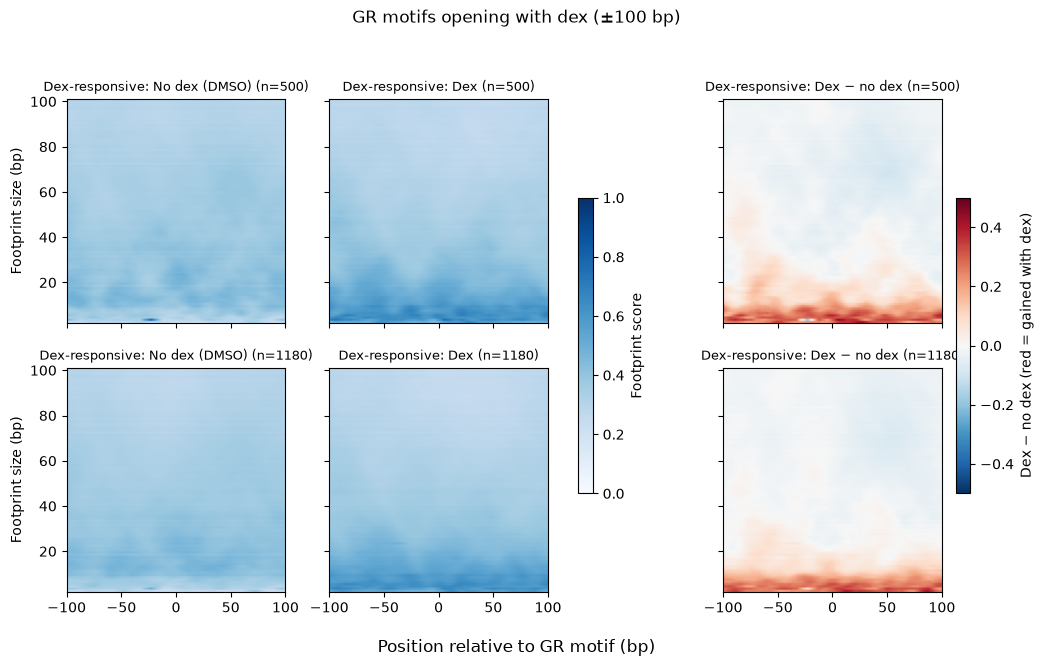

2026-11-18 16:21:38 - INFO - maxp pruned


2026-11-18 16:21:38 - INFO - cmap pruned


2026-11-18 16:21:38 - INFO - kern dropped


2026-11-18 16:21:38 - INFO - post pruned


2026-11-18 16:21:38 - INFO - FFTM dropped


2026-11-18 16:21:38 - INFO - GPOS pruned


... (100 outputs left out)

2026-11-18 16:21:38 - INFO - GDEF pruned


2026-11-18 16:21:38 - INFO - GPOS pruned


2026-11-18 16:21:38 - INFO - GSUB pruned


2026-11-18 16:21:38 - INFO - name pruned


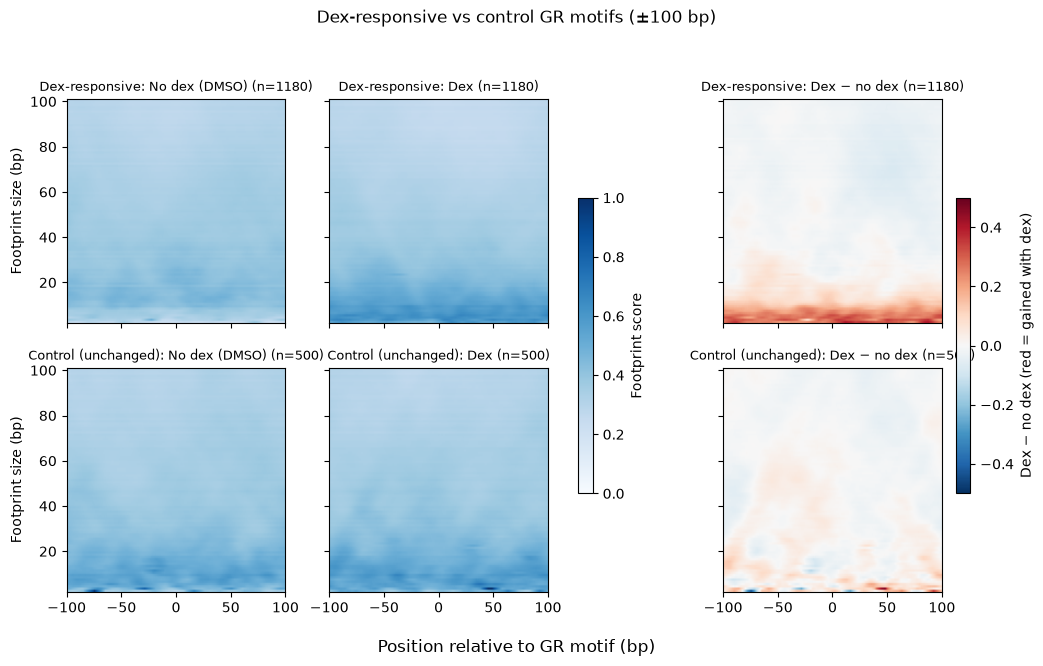

2026-11-18 16:21:41 - INFO - maxp pruned


2026-11-18 16:21:41 - INFO - cmap pruned


2026-11-18 16:21:41 - INFO - kern dropped


2026-11-18 16:21:41 - INFO - post pruned


2026-11-18 16:21:41 - INFO - FFTM dropped


2026-11-18 16:21:41 - INFO - GPOS pruned


... (100 outputs left out)

2026-11-18 16:21:41 - INFO - GDEF pruned


2026-11-18 16:21:41 - INFO - GPOS pruned


2026-11-18 16:21:41 - INFO - GSUB pruned


2026-11-18 16:21:41 - INFO - name pruned


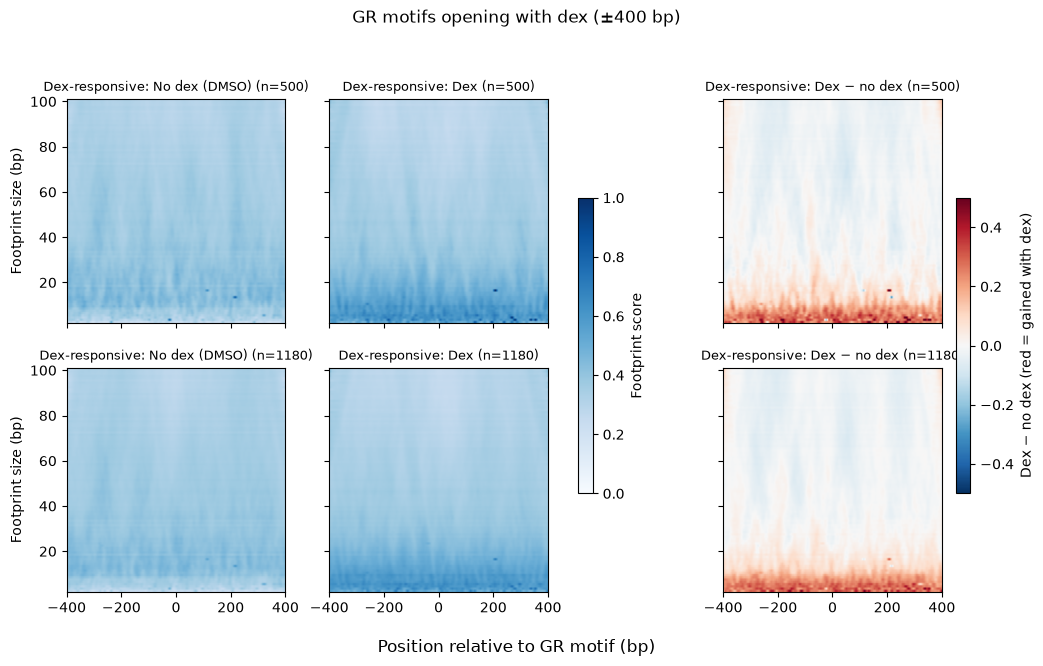

2026-11-18 16:21:44 - INFO - maxp pruned


2026-11-18 16:21:44 - INFO - cmap pruned


2026-11-18 16:21:44 - INFO - kern dropped


2026-11-18 16:21:44 - INFO - post pruned


2026-11-18 16:21:44 - INFO - FFTM dropped


2026-11-18 16:21:44 - INFO - GPOS pruned


... (100 outputs left out)

2026-11-18 16:21:44 - INFO - GDEF pruned


2026-11-18 16:21:44 - INFO - GPOS pruned


2026-11-18 16:21:44 - INFO - GSUB pruned


2026-11-18 16:21:44 - INFO - name pruned


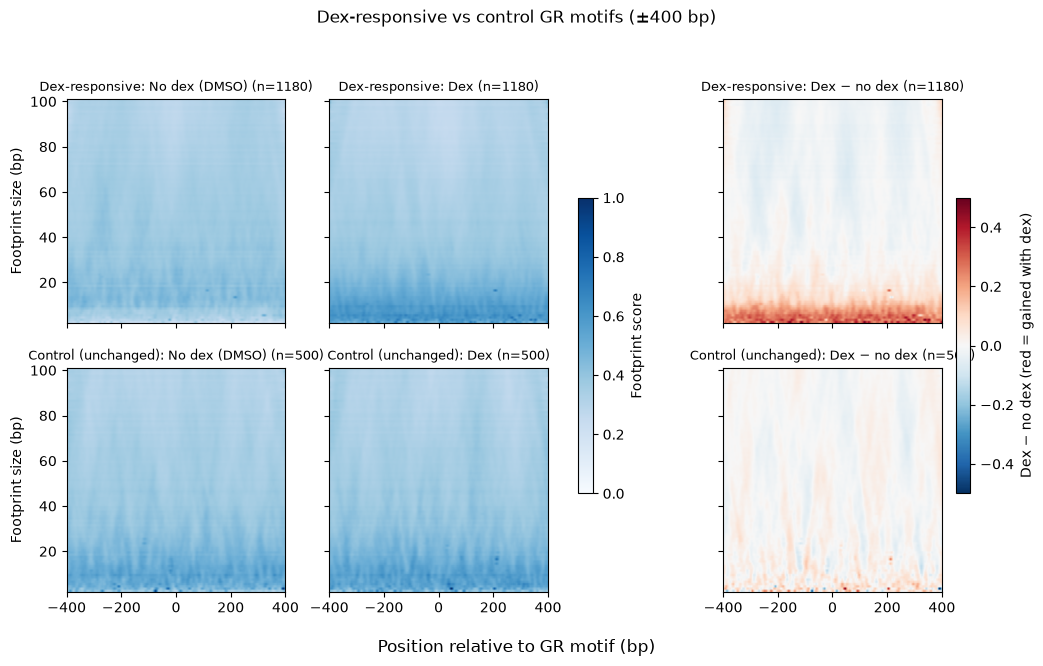

saved arrays: ['dex_responsive_n500_pm100', 'dex_responsive_n1180_pm100', 'control_n500_pm100', 'dex_responsive_n500_pm400', 'dex_responsive_n1180_pm400', 'control_n500_pm400']


In [11]:
# --- Aggregate footprints ---
i_no, i_dex = list(groups2).index("no_dex"), list(groups2).index("dex")
vmax_fp = 1.0        # colour scale for footprint scores (lowered from 2.5 so faint signal is visible)
vmax_diff = 0.5      # colour scale for dex - no dex

def aggregate(set_name, n, half_width, seed=0):
    """Average footprints over n randomly chosen sites of a set (motifs aligned by strand)."""
    s = fp_sets[set_name]
    fp_path = os.path.join(printer.file_path, f"{s['key']}.h5ad")
    n = min(n, len(s["regions"]))
    pick = np.random.default_rng(seed).permutation(len(s["regions"]))[:n]
    total = None
    with h5py.File(fp_path, "r", locking=False) as f:
        for i in pick:
            fp = f["obsm"][s["regions"][i]][:]          # (2 groups, 99 scales, 1000 bp)
            if s["strands"][i] == "-":
                fp = fp[:, :, ::-1]                      # align all motifs in the same direction
            total = fp.astype(np.float64) if total is None else total + fp
    return (total / n)[:, :, 500 - half_width : 500 + half_width], n

def plot_rows(rows, half_width, title, fname):
    """rows: list of (label, avg, n). One row per entry: no dex | dex | dex - no dex."""
    fig, axes = plt.subplots(len(rows), 3, figsize=(12, 3.2 * len(rows)), sharex=True, sharey=True, squeeze=False)
    ext = [-half_width, half_width, 2, 101]
    for r, (label, a, n) in enumerate(rows):
        for c, (idx, cond) in enumerate([(i_no, "No dex (DMSO)"), (i_dex, "Dex")]):
            im = axes[r, c].imshow(a[idx], aspect="auto", origin="lower", cmap="Blues",
                                   vmin=0, vmax=vmax_fp, extent=ext)
            axes[r, c].set_title(f"{label}: {cond} (n={n})", fontsize=9)
        d = axes[r, 2].imshow(a[i_dex] - a[i_no], aspect="auto", origin="lower", cmap="RdBu_r",
                              vmin=-vmax_diff, vmax=vmax_diff, extent=ext)
        axes[r, 2].set_title(f"{label}: Dex − no dex (n={n})", fontsize=9)
        axes[r, 0].set_ylabel("Footprint size (bp)")
    fig.colorbar(im, ax=axes[:, :2], shrink=0.6, label="Footprint score")
    fig.colorbar(d, ax=axes[:, 2], shrink=0.6, label="Dex − no dex (red = gained with dex)")
    fig.supxlabel("Position relative to GR motif (bp)")
    fig.suptitle(title, y=1.02)
    plt.savefig(os.path.join(wd, "plots", fname), bbox_inches="tight")
    plt.show()

saved = {}
for half_width in [100, 400]:            # ±100 bp: GR footprint; ±400 bp: surrounding nucleosomes
    # 1. dex-responsive sites, increasing numbers of sites
    rows = []
    for size in [500, 1500, 3000]:
        a, n = aggregate("dex_responsive", size, half_width)
        if not rows or n > rows[-1][2]:   # skip sizes capped to the same n
            rows.append(("Dex-responsive", a, n)); saved[f"dex_responsive_n{n}_pm{half_width}"] = a
    plot_rows(rows, half_width, f"GR motifs opening with dex (±{half_width} bp)",
              f"aggregate_GR_dex_responsive_pm{half_width}.pdf")

    # 2. dex-responsive (all) vs control
    a_dex, n_dex = aggregate("dex_responsive", max_sites, half_width)
    a_ctl, n_ctl = aggregate("control", n_control, half_width)
    saved[f"control_n{n_ctl}_pm{half_width}"] = a_ctl
    plot_rows([("Dex-responsive", a_dex, n_dex), ("Control (unchanged)", a_ctl, n_ctl)], half_width,
              f"Dex-responsive vs control GR motifs (±{half_width} bp)",
              f"aggregate_GR_vs_control_pm{half_width}.pdf")

# saved inside plots/ so it is collected with the run's results
np.savez(os.path.join(wd, "plots", "GR_aggregate_arrays.npz"), **saved, groups=np.array(groups2))
print("saved arrays:", list(saved))